In [ ]:
from joblib import load
import sys
import seaborn as sns
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
from adjustText import adjust_text
sys.path.append('/home/jhu/jkim789/scratch_aphill27/software/Pooch/pofo_tools/src/')
import pofo_tools
from pofo_tools.utils import *

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

figureDir = "/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/prediction/"
import os 
os.makedirs(figureDir, exist_ok=True)

In [ ]:
mode0 = "models_selection_using_fdr"
mode1 = "models_using_only_knowniDMR_CpGs"
mode2 = "models_using_80_cpg_outside_knowniDMR_fixed"
mode3 = "models_using_80_cpg_outside_knowniDMR_padding2kbp_fixed"
mode4 = "models_using_80_cpg_outside_knowniDMR_padding100kbp"
mode5 = "models_using_80_cpg_outside_knowniDMR_padding1Mbp_fixed"

results_by_mode = {
    mode0: glob.glob(f"/path/to/project/pooch//pooch_data/07.{mode0}/elasticnet_select*"),
    mode1: glob.glob(f"/path/to/project/pooch//pooch_data/07.{mode1}/elasticnet_select*"),
    mode2: glob.glob(f"/path/to/project/pooch/pooch_data/07.{mode2}/elasticnet_select*"),
    mode3: glob.glob(f"/path/to/project/pooch/pooch_data/07.{mode3}/elasticnet_select*"),
    mode4: glob.glob(f"/path/to/project/pooch/pooch_data/07.{mode4}/elasticnet_select*"),
    mode5: glob.glob(f"/path/to/project/pooch/pooch_data/07.{mode5}/elasticnet_select*"),

}

summary = pd.DataFrame()
for mode_name, results in results_by_mode.items():
    for result in results:
        chr_name = result.split("/")[-1].split(".")[0].split("_")[-1]
        temp_df = pd.read_csv(result, sep=",", header=0)
        temp_df["chr"] = chr_name
        temp_df["mode"] = mode_name
        summary = pd.concat([summary, temp_df], ignore_index=True)

summary = summary.loc[summary['chr'] != "chrX"]
summary['chr'] = pd.Categorical(summary['chr'], categories=[f"chr{i}" for i in range(1, 23)], ordered=True)
summary['selected_CpG'] = summary['selected_CpG'].astype(int)

summary.head(2)

,original_CpG,total_CpG,selected_CpG,cv_auc,best_c,best_l1_ratio,Test_Accuracy,Test_Balanced_Accuracy,Test_Brier_Score,chr,mode
0,700566,19267,19267,1.0000,1000.0,0.0,1.0,1.0,2.358291e-09,chr20,models_selection_using_fdr
1,1038930,21242,21242,0.9994,1.0,0.0,1.0,1.0,5.766367e-04,chr16,models_selection_using_fdr


In [ ]:
summary.to_csv("/path/to/project/pooch/findings/outside_iDMR/summary.tsv", sep='\t', header = True, index = False)

In [ ]:
summary['mode'].unique()

<ArrowStringArray>
[                             'models_selection_using_fdr',
                        'models_using_only_knowniDMR_CpGs',
             'models_using_80_cpg_outside_knowniDMR_fixed',
 'models_using_80_cpg_outside_knowniDMR_padding2kbp_fixed',
     'models_using_80_cpg_outside_knowniDMR_padding100kbp',
 'models_using_80_cpg_outside_knowniDMR_padding1Mbp_fixed']
Length: 6, dtype: str

In [ ]:
summary.loc[summary['chr'] != 'chrX'].groupby('mode').agg({'original_CpG': ['sum'],
                            'total_CpG': ['sum'],
                            'selected_CpG': ['sum'], 
                            'Test_Accuracy': ['mean', 'median'], 
                            'Test_Balanced_Accuracy': ['mean', 'median'],
                            'cv_auc': ['mean', 'median'],
                            })

original_CpG total_CpG  \
                                                            sum       sum   
mode                                                                        
models_selection_using_fdr                             25314711    515424   
models_using_80_cpg_outside_knowniDMR_fixed            25302061    493222   
models_using_80_cpg_outside_knowniDMR_padding10...     24953557    454035   
models_using_80_cpg_outside_knowniDMR_padding1M...     22459331    398791   
models_using_80_cpg_outside_knowniDMR_padding2k...     25289349    487324   
models_using_only_knowniDMR_CpGs                          12450     11319   

                                                   selected_CpG Test_Accuracy  \
                                                            sum          mean   
mode                                                                            
models_selection_using_fdr                               119943      0.996829   
models_using_80_cpg_outside_knowniDMR_fixed               27509      0.977776   
models_using_80_cpg_outside_knowniDMR_padding10...        42910      0.950267   
models_using_80_cpg_outside_knowniDMR_padding1M...        15825      0.922757   
models_using_80_cpg_outside_knowniDMR_padding2k...        22309      0.965091   
models_using_only_knowniDMR_CpGs                          10548      0.985852   

                                                              \
                                                      median   
mode                                                           
models_selection_using_fdr                          1.000000   
models_using_80_cpg_outside_knowniDMR_fixed         0.988372   
models_using_80_cpg_outside_knowniDMR_padding10...  0.976190   
models_using_80_cpg_outside_knowniDMR_padding1M...  0.952935   
models_using_80_cpg_outside_knowniDMR_padding2k...  0.988372   
models_using_only_knowniDMR_CpGs                    1.000000   

                                                   Test_Balanced_Accuracy  \
                                                                     mean   
mode                                                                        
models_selection_using_fdr                                       0.996829   
models_using_80_cpg_outside_knowniDMR_fixed                      0.977776   
models_using_80_cpg_outside_knowniDMR_padding10...               0.950267   
models_using_80_cpg_outside_knowniDMR_padding1M...               0.922757   
models_using_80_cpg_outside_knowniDMR_padding2k...               0.965091   
models_using_only_knowniDMR_CpGs                                 0.985852   

                                                                cv_auc  \
                                                      median      mean   
mode                                                                     
models_selection_using_fdr                          1.000000  0.999318   
models_using_80_cpg_outside_knowniDMR_fixed         0.988372  0.995100   
models_using_80_cpg_outside_knowniDMR_padding10...  0.976190  0.976905   
models_using_80_cpg_outside_knowniDMR_padding1M...  0.952935  0.958855   
models_using_80_cpg_outside_knowniDMR_padding2k...  0.988372  0.987050   
models_using_only_knowniDMR_CpGs                    1.000000  0.995736   

                                                             
                                                     median  
mode                                                         
models_selection_using_fdr                          1.00000  
models_using_80_cpg_outside_knowniDMR_fixed         0.99980  
models_using_80_cpg_outside_knowniDMR_padding10...  0.98750  
models_using_80_cpg_outside_knowniDMR_padding1M...  0.98345  
models_using_80_cpg_outside_knowniDMR_padding2k...  0.99980  
models_using_only_knowniDMR_CpGs                    1.00000

In [ ]:
summary.groupby('mode').size()

mode
models_selection_using_fdr                                 22
models_using_80_cpg_outside_knowniDMR_fixed                22
models_using_80_cpg_outside_knowniDMR_padding100kbp        22
models_using_80_cpg_outside_knowniDMR_padding1Mbp_fixed    22
models_using_80_cpg_outside_knowniDMR_padding2kbp_fixed    22
models_using_only_knowniDMR_CpGs                           22
dtype: int64

In [ ]:
color_pallet = {"models_selection_using_fdr": "#0072B2",
                "models_using_only_knowniDMR_CpGs": "#FF7F0E",
                "models_using_80_cpg_outside_knowniDMR_fixed": "#2CA02C",
                "models_using_80_cpg_outside_knowniDMR_padding2kbp_fixed": "#06C5FF",
                "models_using_80_cpg_outside_knowniDMR_padding100kbp": "#D62728",
                "models_using_80_cpg_outside_knowniDMR_padding1Mbp_fixed": "#9467BD"}

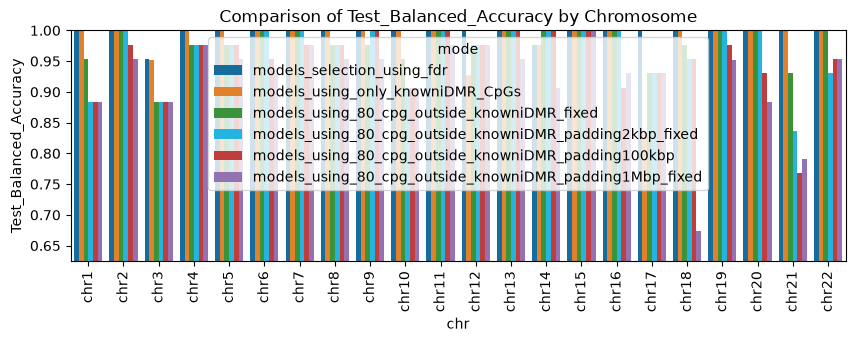

In [ ]:
y = "Test_Balanced_Accuracy" # Test_Balanced_Accuracy Test_Accuracy Test_Brier_Score selected_CpG

plt.figure(figsize=(10, 3))
sns.barplot(x="chr", y=y, data=summary, hue="mode", palette=color_pallet, dodge=True)

if y == "Test_Brier_Score" or y == "selected_CpG":
    plt.ylim(0, max(summary[y]) + 0.05)
else:
    plt.ylim(min(summary[y]) - 0.05, 1)

plt.xticks(rotation=90)
plt.title(f"Comparison of {y} by Chromosome")

plt.savefig(f"{figureDir}/barplot_{y}_{mode1}_vs_{mode2}_vs_{mode3}.pdf")
plt.show()

['models_selection_using_fdr', 'models_using_only_knowniDMR_CpGs', 'models_using_80_cpg_outside_knowniDMR_fixed', 'models_using_80_cpg_outside_knowniDMR_padding2kbp_fixed', 'models_using_80_cpg_outside_knowniDMR_padding100kbp', 'models_using_80_cpg_outside_knowniDMR_padding1Mbp_fixed']


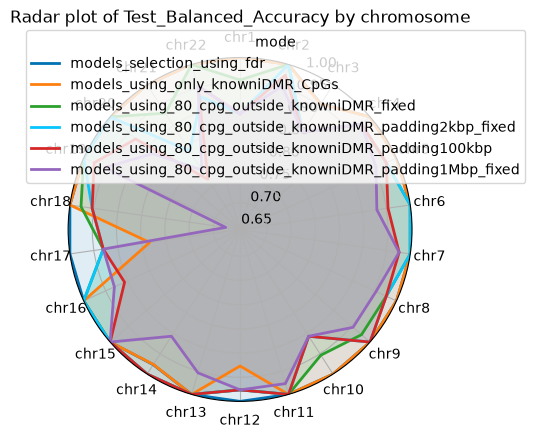

In [ ]:
# radar plot only: Test_Balanced_Accuracy by chromosome, colored by mode

y = "Test_Balanced_Accuracy"
radar_df = summary[["chr", "mode", y]].dropna().copy()
radar_df = radar_df.loc[radar_df['chr'] != 'chrX']  # Exclude chrY if present
radar_df["chr"] = radar_df["chr"].astype(str)

chr_order_all = [f"chr{i}" for i in range(1, 23)] + ["chrX"]
chr_order = [c for c in chr_order_all if c in radar_df["chr"].unique()]
mode_order = radar_df["mode"].drop_duplicates().tolist()
print(mode_order)
# Build equally spaced angles for each chromosome
N = len(chr_order)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(5.5, 5.5), subplot_kw=dict(polar=True))
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(chr_order)

for i, m in enumerate(mode_order):
    vals = []
    mode_df = radar_df[radar_df["mode"] == m]
    by_chr = mode_df.groupby("chr")[y].mean().reindex(chr_order)
    vals = by_chr.fillna(np.nan).tolist()

    # close polygon
    vals += vals[:1]

    ax.plot(angles, vals, linewidth=2, color=color_pallet[m], label=m)
    ax.fill(angles, vals, color=color_pallet[m], alpha=0.12)

vmin = max(0, float(radar_df[y].min()) - 0.03)
vmax = min(1.0, float(radar_df[y].max()) + 0.03)
ax.set_ylim(vmin, vmax)
ax.set_title(f"Radar plot of {y} by chromosome")
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), title="mode")

plt.tight_layout()
plt.savefig(f"{figureDir}/radar_plot_AUC_BalAcc_by_chr_by_diffModes.pdf")
plt.show()